In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("data/data.csv")
df.head()

,Age,BMI,Sex,Height,Weight,Length_of_Stay,Management,Severity,Diagnosis_Presumptive,Diagnosis,...,Abscess_Location,Pathological_Lymph_Nodes,Lymph_Nodes_Location,Bowel_Wall_Thickening,Conglomerate_of_Bowel_Loops,Ileus,Coprostasis,Meteorism,Enteritis,Gynecological_Findings
0,12.68,16.9,female,148.0,37.0,3.0,conservative,uncomplicated,appendicitis,appendicitis,...,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,14.10,31.9,male,147.0,69.5,2.0,conservative,uncomplicated,appendicitis,no appendicitis,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,NaN,NaN
2,14.14,23.3,female,163.0,62.0,4.0,conservative,uncomplicated,appendicitis,no appendicitis,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,yes,NaN
3,16.37,20.6,female,165.0,56.0,3.0,conservative,uncomplicated,appendicitis,no appendicitis,...,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN
4,11.08,16.9,female,163.0,45.0,3.0,conservative,uncomplicated,appendicitis,appendicitis,...,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN


In [4]:
df.shape

(782, 58)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 58 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Age                               781 non-null    float64
 1   BMI                               755 non-null    float64
 2   Sex                               780 non-null    str    
 3   Height                            756 non-null    float64
 4   Weight                            779 non-null    float64
 5   Length_of_Stay                    778 non-null    float64
 6   Management                        781 non-null    str    
 7   Severity                          781 non-null    str    
 8   Diagnosis_Presumptive             780 non-null    str    
 9   Diagnosis                         780 non-null    str    
 10  Alvarado_Score                    730 non-null    float64
 11  Paedriatic_Appendicitis_Score     730 non-null    float64
 12  Appendix_on_US     

In [6]:
df["Diagnosis"].value_counts()

Diagnosis
appendicitis       463
no appendicitis    317
Name: count, dtype: int64

In [7]:
df.isnull().sum().sort_values(ascending=False).head(20)

Abscess_Location               769
Gynecological_Findings         756
Conglomerate_of_Bowel_Loops    739
Segmented_Neutrophils          728
Ileus                          722
Perfusion                      719
Enteritis                      716
Appendicolith                  713
Coprostasis                    711
Perforation                    701
Appendicular_Abscess           697
Bowel_Wall_Thickening          683
Lymph_Nodes_Location           661
Target_Sign                    644
Meteorism                      642
Pathological_Lymph_Nodes       579
Appendix_Wall_Layers           564
Surrounding_Tissue_Reaction    530
Appendix_Diameter              284
RBC_in_Urine                   206
dtype: int64

## Observations so far
- Dataset has 782 rows and 58 columns
- Target is Diagnosis: 463 appendicitis, 317 no appendicitis (fairly balanced)
- 2 rows have no diagnosis
- Most of the heavily missing columns are ultrasound findings, so using only clinical and lab features
- Segmented_Neutrophils is a lab column but almost fully empty

In [8]:
df = df.dropna(subset=["Diagnosis"])
df.shape

(780, 58)

In [9]:
leak_cols = ["Management", "Severity", "Diagnosis_Presumptive", "Length_of_Stay"]
df = df.drop(columns=leak_cols)
df.shape

(780, 54)

In [10]:
us_cols = [
    "Abscess_Location", "Gynecological_Findings", "Conglomerate_of_Bowel_Loops",
    "Ileus", "Perfusion", "Enteritis", "Appendicolith", "Coprostasis",
    "Perforation", "Appendicular_Abscess", "Bowel_Wall_Thickening",
    "Lymph_Nodes_Location", "Target_Sign", "Meteorism",
    "Pathological_Lymph_Nodes", "Appendix_Wall_Layers",
    "Surrounding_Tissue_Reaction", "Appendix_Diameter", "Free_Fluids",
    "US_Number", "Appendix_on_US", "US_Performed",
]
df = df.drop(columns=us_cols)
df.shape

(780, 32)

## Cleaning so far
- Dropped 2 rows with no diagnosis (780 rows left)
- Dropped Management, Severity, Diagnosis_Presumptive because they leak the answer
- Dropped all 22 ultrasound columns, 33 columns left

In [11]:
df = df.drop(columns=["Segmented_Neutrophils"])
df.shape

(780, 31)

In [12]:
df = df.drop(columns=["Alvarado_Score", "Paedriatic_Appendicitis_Score"])
df.shape

(780, 29)

In [13]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

RBC_in_Urine                        204
Ketones_in_Urine                    198
WBC_in_Urine                        197
Ipsilateral_Rebound_Tenderness      161
Neutrophil_Percentage               101
Neutrophilia                         48
Psoas_Sign                           35
Dysuria                              27
BMI                                  26
Height                               25
RDW                                  24
RBC_Count                            16
Thrombocyte_Count                    16
Hemoglobin                           16
Stool                                15
Coughing_Pain                        14
Contralateral_Rebound_Tenderness     13
CRP                                   9
Loss_of_Appetite                      8
Peritonitis                           7
Migratory_Pain                        7
Nausea                                6
Lower_Right_Abd_Pain                  6
Body_Temperature                      5
WBC_Count                             4


In [14]:
(204/780) * 100

26.153846153846157

In [15]:
X = df.drop(columns=["Diagnosis"])
y = df["Diagnosis"]
print(X.shape, y.shape)
y.value_counts()

(780, 28) (780,)


Diagnosis
appendicitis       463
no appendicitis    317
Name: count, dtype: int64

In [16]:
from sklearn.model_selection import train_test_split
y = y.map({
    "appendicitis": 1,
    "no appendicitis": 0
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(624, 28) (156, 28)
Diagnosis
1    370
0    254
Name: count, dtype: int64
Diagnosis
1    93
0    63
Name: count, dtype: int64


## Cleaning and Split
- Dropped Segmented_Neutrophils (almost fully empty)
- Dropped Alvarado_Score and Paedriatic_Appendicitis_Score (calculated from the same features)
- Dropped Length_of_Stay (only known after treatment, so it leaks the outcome)
- X has 28 features, y is 1 for appendicitis and 0 for no appendicitis

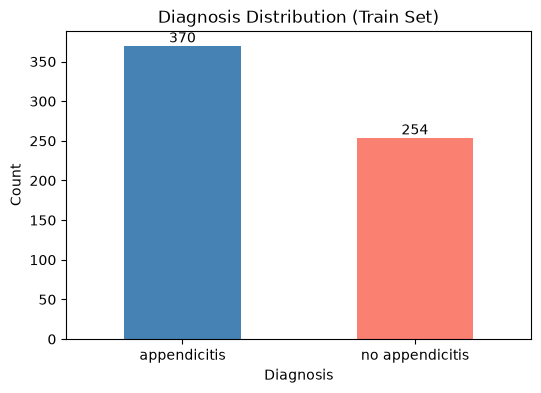

In [28]:
counts = y_train.map({1: "appendicitis", 0: "no appendicitis"}).value_counts()

ax = counts.plot(kind="bar", color=["steelblue", "salmon"], figsize=(6, 4))
ax.bar_label(ax.containers[0])
plt.title("Diagnosis Distribution (Train Set)")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

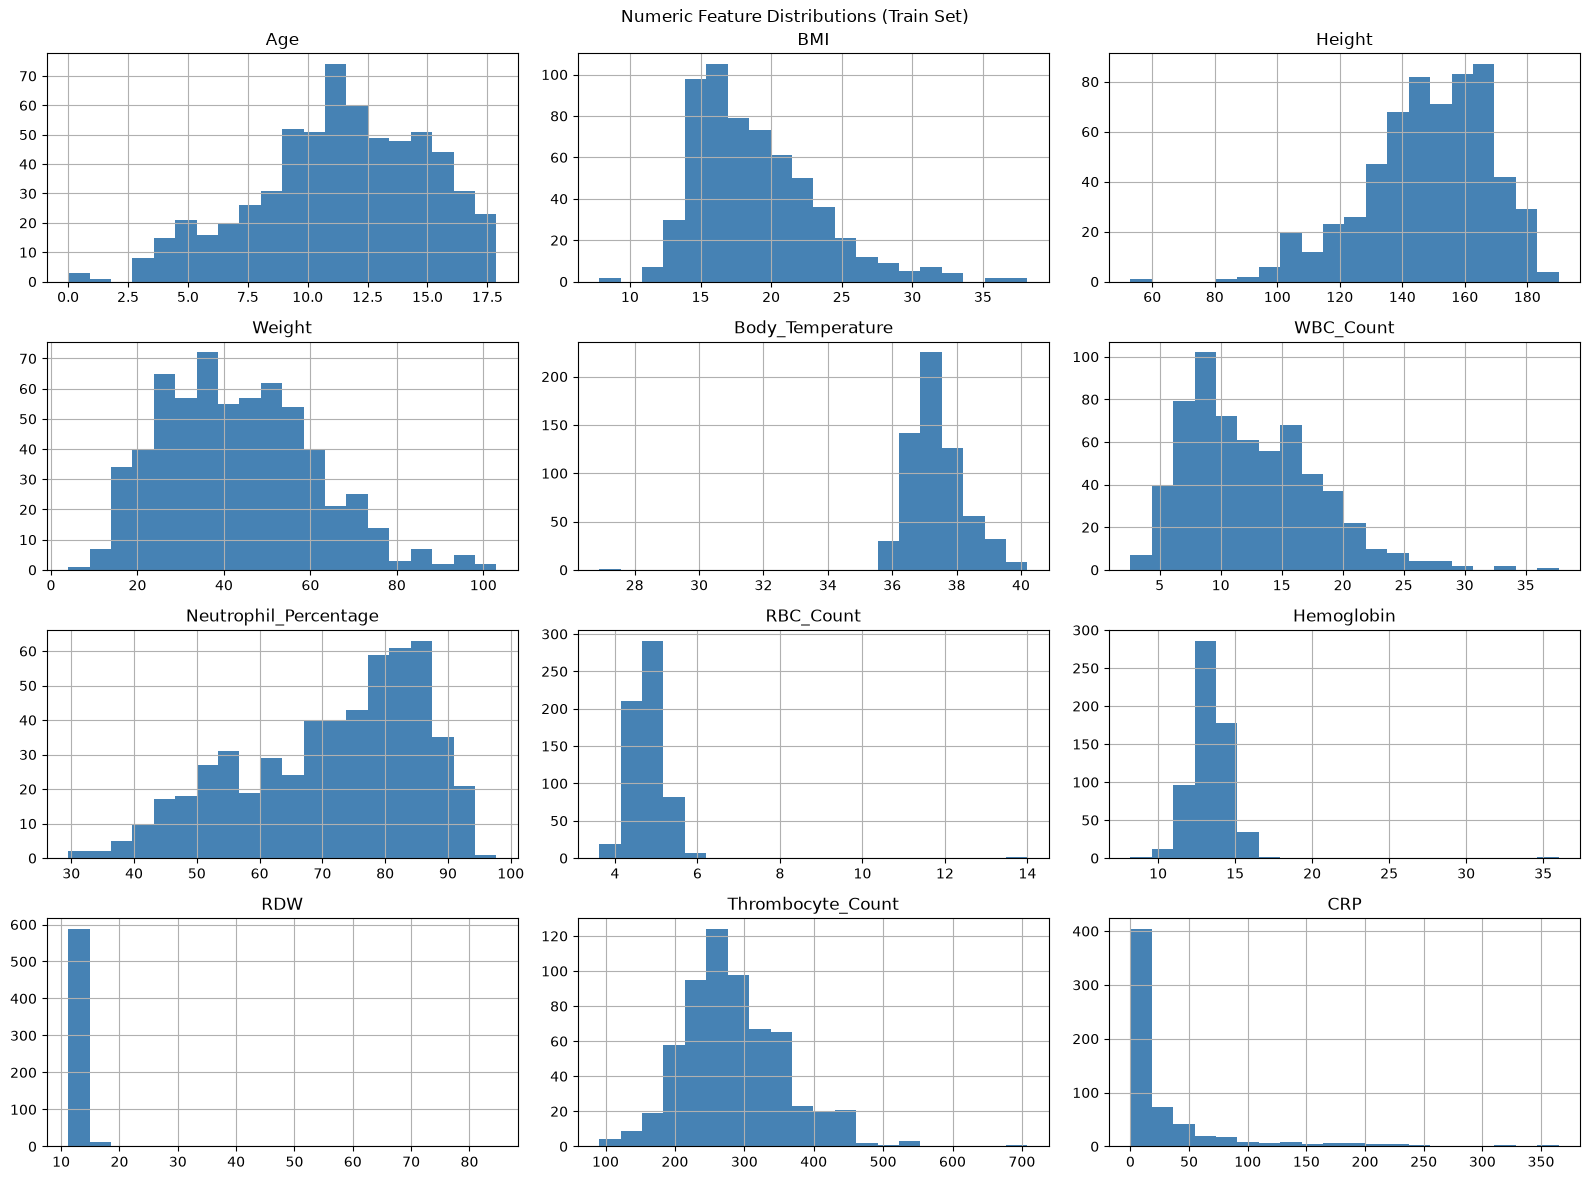

In [32]:
X_train[num_cols].hist(bins=20, figsize=(16, 12), color="steelblue")
plt.suptitle("Numeric Feature Distributions (Train Set)")
plt.tight_layout()
plt.show()

In [37]:
X_train[num_cols].describe().loc[["min", "50%", "max"]].round(2)

,Age,BMI,Height,Weight,Body_Temperature,WBC_Count,Neutrophil_Percentage,RBC_Count,Hemoglobin,RDW,Thrombocyte_Count,CRP
min,0.00,7.83,53.0,3.96,26.9,2.6,29.5,3.62,8.2,11.2,91.0,0.0
50%,11.45,18.03,150.0,42.00,37.2,11.6,74.9,4.78,13.3,12.8,275.5,7.0
max,17.87,38.16,190.0,103.00,40.2,37.7,97.7,14.00,36.0,84.6,708.0,365.0


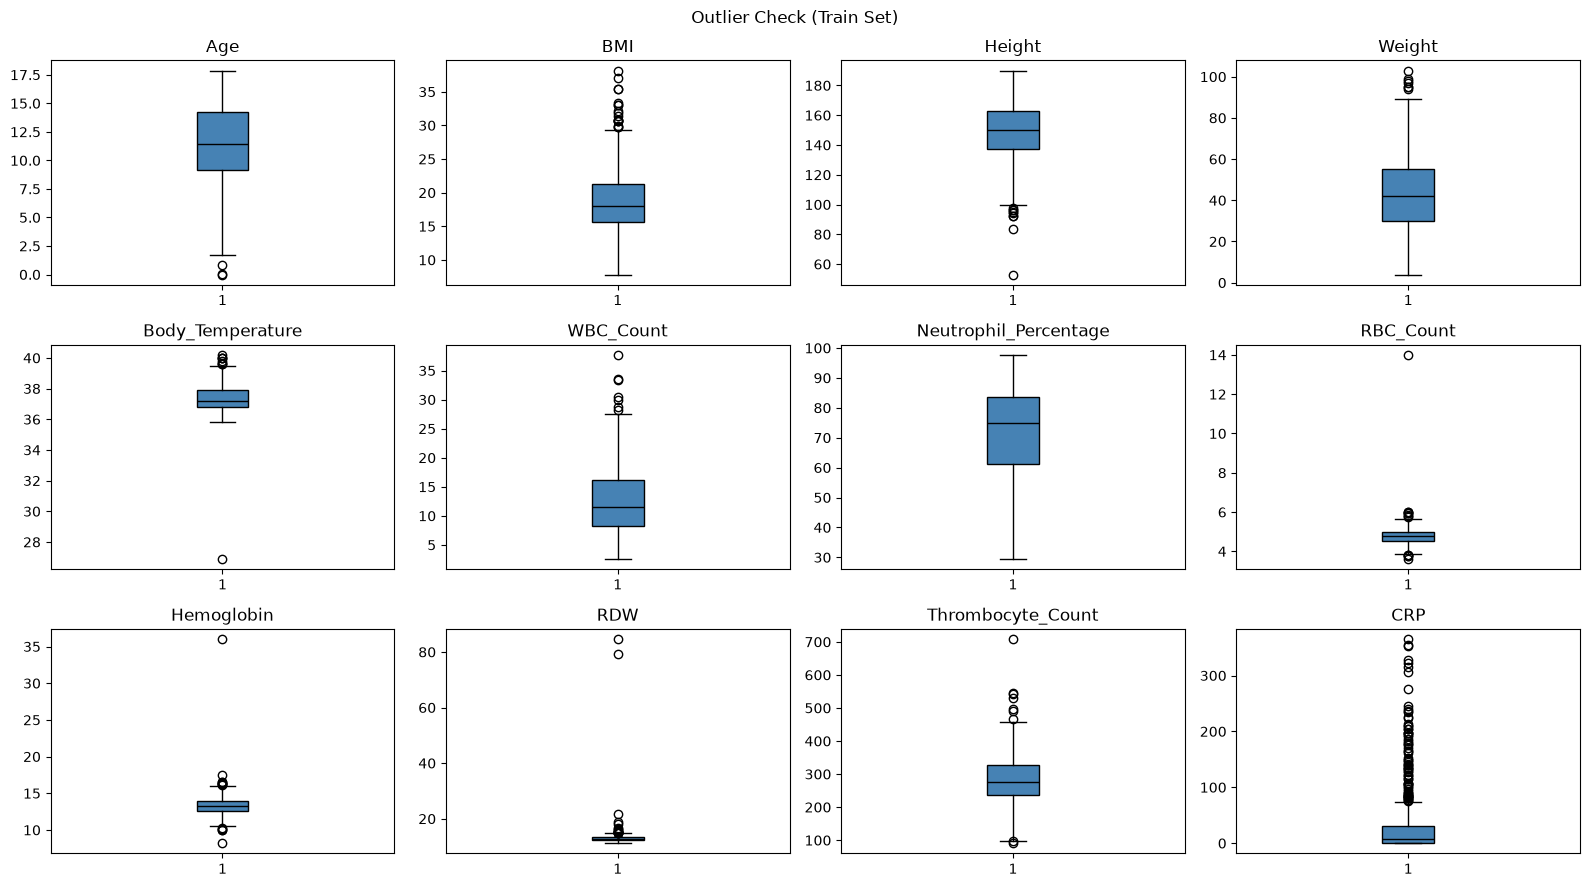

In [38]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    ax.boxplot(X_train[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor="steelblue"),
               medianprops=dict(color="black"))
    ax.set_title(col)
plt.suptitle("Outlier Check (Train Set)")
plt.tight_layout()
plt.show()

In [39]:
limits = {
    "Body_Temperature": (33, 43),
    "RBC_Count": (2, 8),
    "Hemoglobin": (5, 20),
    "RDW": (10, 25),
}
for col, (lo, hi) in limits.items():
    bad = (X_train[col] < lo) | (X_train[col] > hi)
    print(col, "train rows fixed:", bad.sum())
    for d in (X_train, X_test):
        d.loc[(d[col] < lo) | (d[col] > hi), col] = np.nan

Body_Temperature train rows fixed: 1
RBC_Count train rows fixed: 1
Hemoglobin train rows fixed: 1
RDW train rows fixed: 2


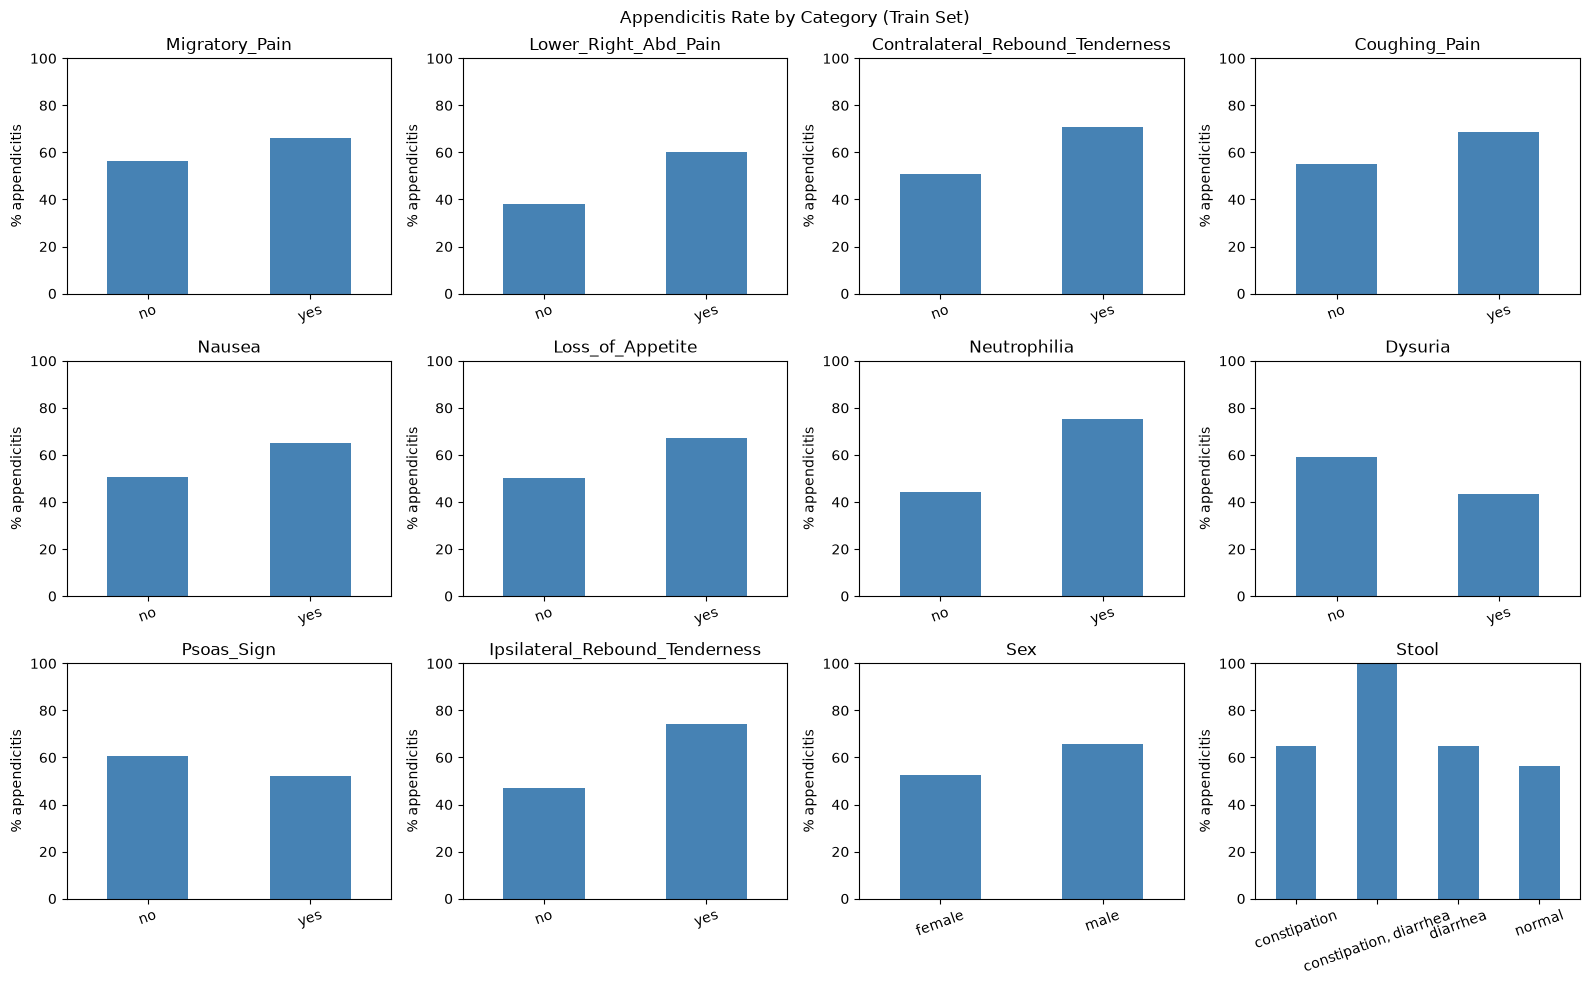

In [40]:
cat_plot_cols = binary_cols + ["Sex", "Stool"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, cat_plot_cols):
    rate = y_train.groupby(X_train[col]).mean() * 100
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("% appendicitis")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("Appendicitis Rate by Category (Train Set)")
plt.tight_layout()
plt.show()

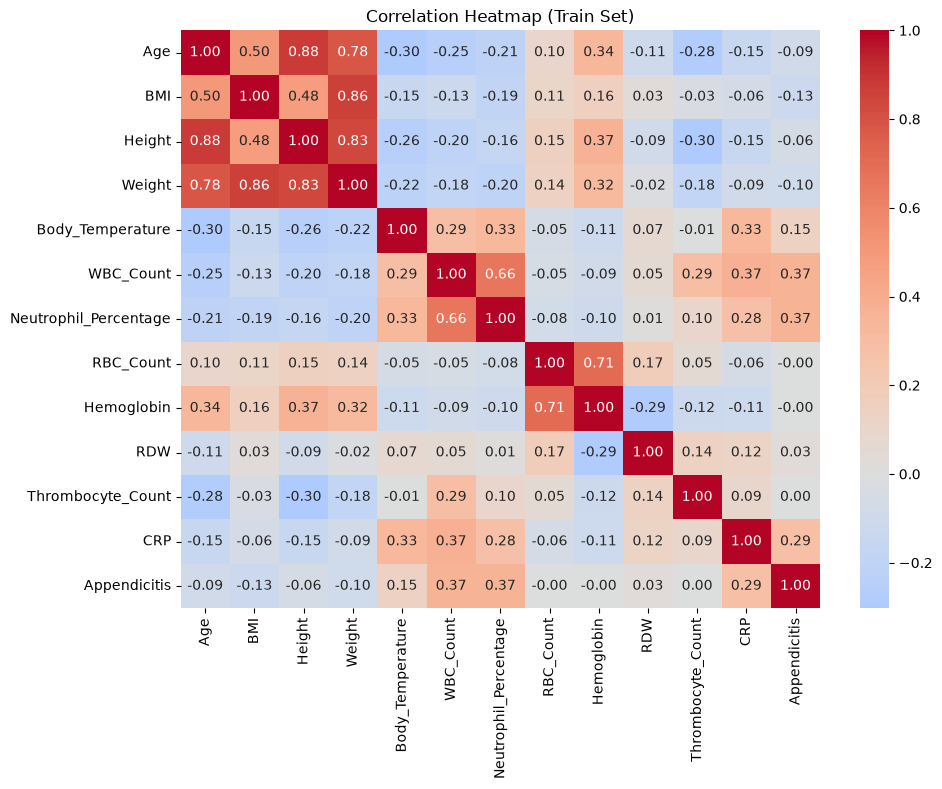

Stool
normal                    443
diarrhea                  105
constipation               63
constipation, diarrhea      1
Name: count, dtype: int64


In [41]:
corr = X_train[num_cols].assign(Appendicitis=y_train).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Train Set)")
plt.tight_layout()
plt.show()

print(X_train["Stool"].value_counts())

## EDA findings (train set)
- Classes are mildly imbalanced (370 vs 254), no special handling needed
- Impossible values found in Body_Temperature, RBC_Count, Hemoglobin and RDW, set to missing so the imputer fills them
- Real extremes in CRP, WBC_Count and BMI kept, since high CRP and WBC are real signs of appendicitis
- Strongest signals: Neutrophilia, rebound tenderness, lower right abdominal pain, WBC, neutrophil percentage, CRP
- Dysuria and Psoas_Sign have lower appendicitis rates when present
- Age, Height, Weight and BMI are highly correlated, so Ridge/Lasso should help for logistic regression
- Stool category "constipation, diarrhea" has only 1 patient, so its 100% appendicitis rate is not reliable

In [18]:
for col in X_train.select_dtypes(exclude="number").columns:
    print(col, X_train[col].unique())

Sex <ArrowStringArray>
['male', 'female', nan]
Length: 3, dtype: str
Migratory_Pain <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
Lower_Right_Abd_Pain <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
Contralateral_Rebound_Tenderness <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
Coughing_Pain <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
Nausea <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
Loss_of_Appetite <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
Neutrophilia <ArrowStringArray>
['yes', 'no', nan]
Length: 3, dtype: str
Ketones_in_Urine <ArrowStringArray>
[nan, '+', 'no', '+++', '++']
Length: 5, dtype: str
RBC_in_Urine <ArrowStringArray>
[nan, 'no', '+++', '+', '++']
Length: 5, dtype: str
WBC_in_Urine <ArrowStringArray>
[nan, 'no', '++', '+', '+++']
Length: 5, dtype: str
Dysuria <ArrowStringArray>
['no', 'yes', nan]
Length: 3, dtype: str
Stool <ArrowStringArray>
['diarrhea', 'normal', 'constipation', nan

In [19]:
df.isnull().sum().sort_values(ascending=False)

RBC_in_Urine                        204
Ketones_in_Urine                    198
WBC_in_Urine                        197
Ipsilateral_Rebound_Tenderness      161
Neutrophil_Percentage               101
Neutrophilia                         48
Psoas_Sign                           35
Dysuria                              27
BMI                                  26
Height                               25
RDW                                  24
Thrombocyte_Count                    16
RBC_Count                            16
Hemoglobin                           16
Stool                                15
Coughing_Pain                        14
Contralateral_Rebound_Tenderness     13
CRP                                   9
Loss_of_Appetite                      8
Peritonitis                           7
Migratory_Pain                        7
Nausea                                6
Lower_Right_Abd_Pain                  6
Body_Temperature                      5
WBC_Count                             4


In [20]:
binary_cols = [
    "Migratory_Pain", "Lower_Right_Abd_Pain", "Contralateral_Rebound_Tenderness",
    "Coughing_Pain", "Nausea", "Loss_of_Appetite", "Neutrophilia", "Dysuria",
    "Psoas_Sign", "Ipsilateral_Rebound_Tenderness",
]
ordinal_cols = ["Ketones_in_Urine", "RBC_in_Urine", "WBC_in_Urine", "Peritonitis"]
onehot_cols = ["Sex", "Stool"]
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print(len(binary_cols), len(ordinal_cols), len(onehot_cols), len(num_cols))

10 4 2 12


In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

binary_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[["no", "yes"]] * len(binary_cols))),
])

In [22]:
ordinal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[
        ["no", "+", "++", "+++"],
        ["no", "+", "++", "+++"],
        ["no", "+", "++", "+++"],
        ["no", "local", "generalized"],
    ])),
])

In [23]:
from sklearn.preprocessing import OneHotEncoder

onehot_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

In [24]:
from sklearn.preprocessing import StandardScaler

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

In [25]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("binary", binary_pipe, binary_cols),
    ("ordinal", ordinal_pipe, ordinal_cols),
    ("onehot", onehot_pipe, onehot_cols),
    ("num", num_pipe, num_cols),
])

In [26]:
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print(X_train_p.shape, X_test_p.shape)
print(np.isnan(X_train_p).sum(), np.isnan(X_test_p).sum())

(624, 32) (156, 32)
0 0


## Preprocessing
- Yes/no columns: mode fill, then mapped to 0/1
- Urine tests and Peritonitis: mode fill, then ordinal encode (no < + < ++ < +++, no < local < generalized)
- Sex and Stool: mode fill, then one-hot encode
- Numeric columns: median fill, then standard scaling
- Everything is fitted on train only, so the test set stays clean
- Result: 32 features, no missing values

BMI                     -0.129
Weight                  -0.097
Age                     -0.086
Height                  -0.056
Hemoglobin              -0.003
RBC_Count               -0.002
Thrombocyte_Count        0.001
RDW                      0.025
Body_Temperature         0.149
CRP                      0.285
Neutrophil_Percentage    0.368
WBC_Count                0.368
dtype: float64


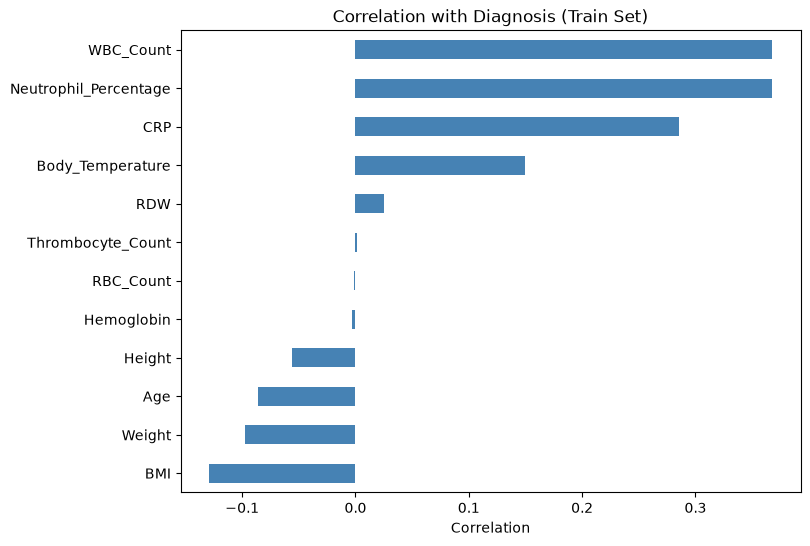

In [45]:
# correlation of each numeric feature with the 0/1 diagnosis
corr_target = X_train[num_cols].corrwith(y_train).sort_values()
print(corr_target.round(3))

# horizontal bar plot, sorted from most negative to most positive
corr_target.plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Correlation with Diagnosis (Train Set)")
plt.xlabel("Correlation")
plt.show()

In [42]:
from sklearn.linear_model import LogisticRegression

# learn imputation, encoding and scaling from train, then apply to both sets
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print(X_train_p.shape, X_test_p.shape)

# create and train a baseline logistic regression model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_p, y_train)

# compare train and test accuracy to check for overfitting
print("Train accuracy:", round(log_reg.score(X_train_p, y_train), 3))
print("Test accuracy:", round(log_reg.score(X_test_p, y_test), 3))

(624, 32) (156, 32)
Train accuracy: 0.768
Test accuracy: 0.679


In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# models to compare, including a dummy that always guesses the majority class
models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(random_state=42),
}

# train each model and record train and test accuracy
rows = []
for name, model in models.items():
    model.fit(X_train_p, y_train)
    rows.append([name,
                 round(model.score(X_train_p, y_train), 3),
                 round(model.score(X_test_p, y_test), 3)])

# show results as a table with the gap between train and test
results = pd.DataFrame(rows, columns=["Model", "Train acc", "Test acc"])
results["Gap"] = (results["Train acc"] - results["Test acc"]).round(3)
results

,Model,Train acc,Test acc,Gap
0,Dummy (majority),0.593,0.596,-0.003
1,Logistic Regression,0.768,0.679,0.089
2,KNN (k=5),0.771,0.667,0.104
3,Decision Tree,1.000,0.667,0.333
4,Random Forest,1.000,0.750,0.250
5,SVM,0.824,0.667,0.157


In [44]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

# 5 folds that keep the class ratio the same in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# the preprocessor is inside the pipeline, so it is refit on each fold's training part
cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append([name, round(scores.mean(), 3), round(scores.std(), 3)])

# average accuracy and spread across the 5 folds
cv_results = pd.DataFrame(cv_rows, columns=["Model", "CV mean", "CV std"])
cv_results

,Model,CV mean,CV std
0,Dummy (majority),0.593,0.002
1,Logistic Regression,0.745,0.037
2,KNN (k=5),0.647,0.013
3,Decision Tree,0.657,0.038
4,Random Forest,0.736,0.051
5,SVM,0.742,0.048
